# Session-wise training — one model per session, and leave-one-session-out

Two designs, both run on the same data with the same nine regression methods as `complete_results.ipynb`.

**Design A — one model per session.** Each session is trained on its own, scored inside that session
(leave-one-concentration-out) and on the sessions it never saw, and the per-session results are averaged.
**Session 1 cannot be trained alone.** Its only calibration plate is RB100 at 0 % chicory; the rest of
session 1 is A, B, C (unknown composition) and CH100 (outside the 0–50 % range). A regression needs at least
three concentration levels, so design A trains sessions 2 and 3 only, and says so when it runs.

**Design B — leave-one-session-out (LOSO).** Three folds. Each fold holds out one whole session, trains on the
other two, and predicts the held-out one. The three held-out errors are averaged into the final score, and the
three fold models' predictions for A, B and C are averaged into the final prediction.

**Selection rule:** the model with the lowest mean plate-level RMSEP over the three held-out sessions. Every
figure after the comparison shows that model alone.

Everything else is the existing pipeline: 1000–2450 nm, absorbance + per-spectrum offset removal, worst 10 % of
patches dropped per plate, super-patches of 8, PLSR at 6 LV, and the other eight methods at the settings used
before. One deliberate change: the trimming model is refitted **inside every fold on the training sessions
only**, so a held-out session never influences its own preprocessing.

Outputs go to `session_results/`.

## 1. Setup

In [1]:
import os
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------- EDIT -------------------------------
BASE    = Path(os.environ.get("COFFEE_DATA", "."))
OLD_CSV = BASE / "samples_out" / "training_samples.csv"     # sessions 1 and 2
NEW_CSV = BASE / "batch3_out"  / "training_samples.csv"     # session 3
OUT     = BASE / "session_results"
WL_MIN, WL_MAX = 1000.0, 2450.0
TRIM_PCT, K_UNIT, N_COMP = 10, 8, 6        # identical to the final model
N_BOOT  = 2000                             # bootstrap draws for the best-vs-runner-up check
# ---------------------------------------------------------------------

OUT.mkdir(exist_ok=True, parents=True)
RNG = np.random.default_rng(0)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S_COLOR  = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}   # one colour per session, same in every figure
S_MARKER = {1: "o", 2: "s", 3: "^"}                     # and one marker, so colour is never the only cue
HIGHLIGHT, OTHER = "#2a78d6", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})
BANDS = [(1450, "O–H water"), (1730, "C–H lipid"), (1940, "O–H water"),
         (2100, "C–O carbohydrate"), (2310, "C–H combination")]
print("sessions 1-2 csv:", OLD_CSV.exists(), "| session 3 csv:", NEW_CSV.exists())

sessions 1-2 csv: True | session 3 csv: True


## 2. Data

In [2]:
def load(path, tag=None):
    d = pd.read_csv(path)
    d = d[d.label != "AB100"].reset_index(drop=True)          # arabica is not part of this model
    if tag:
        for c in ("scan", "group", "plate"):
            d[c] = d[c].astype(str) + tag
    return d

DATA = pd.concat([load(OLD_CSV), load(NEW_CSV, "_b3")], ignore_index=True)
DATA["session"] = DATA["day"].astype(int)

wc = [c for c in DATA.columns if c.replace(".", "", 1).isdigit()]
wl_all = np.array([float(c) for c in wc])
BM = (wl_all >= WL_MIN) & (wl_all <= WL_MAX)
WL, COLS = wl_all[BM], [c for c, k in zip(wc, BM) if k]

def preprocess(R):
    # absorbance, then remove each spectrum's own offset -- identical to the final model
    R = np.clip(np.asarray(R, float), 1e-3, None)
    Z = np.log10(1.0 / R)
    return Z - Z.mean(-1, keepdims=True)

Z       = preprocess(DATA[COLS].values)
SESSION = DATA["session"].to_numpy()
GROUP   = DATA["group"].astype(str).to_numpy()
LABEL   = DATA["label"].astype(str).to_numpy()
CAL     = (DATA["role"] == "calibration").to_numpy()
Y       = DATA["chicory_pct"].to_numpy(float)
LEVELS  = {s: sorted(set(Y[CAL & (SESSION == s)])) for s in (1, 2, 3)}

print(f"{len(DATA)} patches | {len(set(GROUP))} plates | {len(WL)} bands ({WL[0]:.0f}-{WL[-1]:.0f} nm)\n")
for s in (1, 2, 3):
    print(f"session {s}: calibration levels {[int(v) for v in LEVELS[s]]}"
          f"  | plates: {', '.join(sorted(set(LABEL[SESSION == s])))}")

6633 patches | 45 plates | 266 bands (1001-2446 nm)

session 1: calibration levels [0]  | plates: A, B, C, CH100, RB100
session 2: calibration levels [10, 20, 30, 40, 50]  | plates: RB[50:50], RB[60:40], RB[70:30], RB[80:20], RB[90:10]
session 3: calibration levels [5, 15, 25, 35, 45]  | plates: RB[55:45], RB[65:35], RB[75:25], RB[85:15], RB[95:5]


## 3. Building blocks

`units()` is the trimming and super-patch step from the earlier notebooks, with one change: the trimming model
is fitted on the **training sessions only** and then applied to every plate. Ranking is still done within each
plate, so a held-out session is never removed wholesale for having a higher residual.

Scores are reported at three levels. **Plate** (one dish in one stir) is the primary one and the one used for
selection. **Sample** (one blend, all three stirs pooled) is the level the earlier RMSEP of 1.16 % was quoted at.

In [3]:
META = ["session", "capture", "label", "group", "role", "chicory_pct", "patch_row", "patch_col"]
_UNITS = {}

def units(train_sessions, k=K_UNIT):
    key = tuple(sorted(train_sessions))
    if key in _UNITS:
        return _UNITS[key]
    tr = CAL & np.isin(SESSION, key)
    ref = PLSRegression(n_components=4).fit(Z[tr], Y[tr])
    mu = Z[tr].mean(0)
    T = (Z - mu) @ ref.x_rotations_
    q = np.sum(((Z - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
    keep = pd.Series(q).groupby(GROUP).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
    idx = []
    for g in pd.unique(GROUP):
        ii = np.where((GROUP == g) & keep)[0]
        if len(ii) < k:
            continue
        n = max(1, len(ii) // k)
        lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(
            DATA.loc[ii, ["patch_row", "patch_col"]].to_numpy(float))
        idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
    ZU = np.array([Z[i].mean(0) for i in idx])
    UM = DATA.iloc[[i[0] for i in idx]][META].reset_index(drop=True)
    UM["n_patches"] = [len(i) for i in idx]
    _UNITS[key] = (ZU, UM)
    return ZU, UM

# the same nine methods and settings as complete_results.ipynb
MODELS = {
    "PLSR 6 LV":         lambda: PLSRegression(n_components=N_COMP),
    "PLSR 3 LV":         lambda: PLSRegression(n_components=3),
    "PCR (PCA+OLS)":     lambda: make_pipeline(PCA(n_components=N_COMP), LinearRegression()),
    "Ridge":             lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "ElasticNet":        lambda: make_pipeline(StandardScaler(), ElasticNet(alpha=.01, l1_ratio=.5, max_iter=5000)),
    "SVR (linear)":      lambda: make_pipeline(StandardScaler(), SVR(kernel="linear", C=10)),
    "SVR (RBF)":         lambda: make_pipeline(StandardScaler(), SVR(kernel="rbf", C=100, gamma="scale")),
    "Random Forest":     lambda: RandomForestRegressor(n_estimators=120, random_state=0, n_jobs=-1),
    "Gradient Boosting": lambda: GradientBoostingRegressor(n_estimators=100, random_state=0),
}

def fit(name, X, y):
    return MODELS[name]().fit(X, y)

def predict(model, X):
    return np.asarray(model.predict(X)).ravel()

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def score(d):
    plate  = d.groupby(["group", "y"], as_index=False)["p"].mean()
    sample = d.groupby(["label", "y"], as_index=False)["p"].mean()
    out = dict(levels=int(d.y.nunique()), plates=len(plate), units=len(d),
               rmsep_unit=rmse(d.y, d.p), rmsep_plate=rmse(plate.y, plate.p),
               rmsep_sample=rmse(sample.y, sample.p), bias=float((plate.p - plate.y).mean()),
               r2=np.nan, slope=np.nan, intercept=np.nan)
    if d.y.nunique() >= 3:                     # one level has no slope and no R²
        out["r2"] = float(r2_score(plate.y, plate.p))
        out["slope"], out["intercept"] = map(float, np.polyfit(plate.y, plate.p, 1))
    return out

def frame(UM, mask, p, **tags):
    d = UM.loc[mask, ["session", "label", "group", "role", "chicory_pct"]].rename(columns={"chicory_pct": "y"})
    d["p"] = p
    for k_, v in tags.items():
        d[k_] = v
    return d

def linear_coef(m):
    # coefficients in the preprocessed-spectrum space, for the methods that have them
    if isinstance(m, PLSRegression):
        c = np.asarray(m.coef_)
        return c.ravel() if c.size == WL.size else c.T.ravel()
    if isinstance(m, Pipeline):
        steps, last = m.named_steps, m.steps[-1][1]
        if isinstance(last, LinearRegression) and "pca" in steps:
            return steps["pca"].components_.T @ np.ravel(last.coef_)
        if "standardscaler" in steps and hasattr(last, "coef_"):
            return np.ravel(last.coef_) / steps["standardscaler"].scale_
    return None

## 4. Design A — one model per session

For every session that has enough levels: leave-one-concentration-out **within** the session, then a model fitted
on the whole session predicts the calibration plates of the other sessions and the session-1 samples (A, B, C,
CH100). The per-session transfer score pools every calibration plate the model never saw.

Each session model extrapolates a little on the others: session 2 covers 10–50 %, so it extrapolates to 0 % and
5 %; session 3 covers 5–45 %, so it extrapolates to 0 % and 50 %.

In [4]:
TRAINABLE = [s for s in (1, 2, 3) if len(LEVELS[s]) >= 3]
for s in (1, 2, 3):
    if s not in TRAINABLE:
        print(f"session {s}: SKIPPED -- {len(LEVELS[s])} calibration level(s) {[int(v) for v in LEVELS[s]]}; "
              "a regression cannot be fitted to a single concentration")
print("trained separately:", [f"session {s}" for s in TRAINABLE], "\n")

PS_ROWS, PS_PRED = [], []
for s in TRAINABLE:
    ZU, UM = units([s])
    us, ucal = UM.session.to_numpy(), (UM.role == "calibration").to_numpy()
    y = UM.chicory_pct.to_numpy(float)
    tr = ucal & (us == s)
    unk = (us == 1) & ~ucal
    for name in MODELS:
        p = np.full(tr.sum(), np.nan)
        for a, b in LeaveOneGroupOut().split(ZU[tr], y[tr], groups=y[tr]):
            p[b] = predict(fit(name, ZU[tr][a], y[tr][a]), ZU[tr][b])
        d = frame(UM, tr, p, model=name, train=s, test=s, kind="calibration")
        PS_PRED.append(d)
        PS_ROWS.append(dict(model=name, train=s, test=s, within=True, **score(d)))

        m = fit(name, ZU[tr], y[tr])
        for t in (1, 2, 3):
            if t == s:
                continue
            te = ucal & (us == t)
            d = frame(UM, te, predict(m, ZU[te]), model=name, train=s, test=t, kind="calibration")
            PS_PRED.append(d)
            PS_ROWS.append(dict(model=name, train=s, test=t, within=False, **score(d)))
        PS_PRED.append(frame(UM, unk, predict(m, ZU[unk]), model=name, train=s, test=1, kind="unknown"))

PS_ROWS = pd.DataFrame(PS_ROWS)
PS_PRED = pd.concat(PS_PRED, ignore_index=True)
seen_not = PS_PRED[(PS_PRED.kind == "calibration") & (PS_PRED.test != PS_PRED.train)]
PS_TRANSFER = pd.DataFrame([dict(model=n, train=s, **score(d)) for (n, s), d in seen_not.groupby(["model", "train"])])

for s in TRAINABLE:
    t = (PS_ROWS[PS_ROWS.train == s]
         .pivot(index="model", columns="test", values="rmsep_plate")
         .rename(columns=lambda c: f"session {c}" + (" (CV)" if c == s else "")))
    t["other sessions pooled"] = PS_TRANSFER[PS_TRANSFER.train == s].set_index("model").rmsep_plate
    print(f"--- trained on session {s} only, levels {[int(v) for v in LEVELS[s]]}: plate RMSEP (% chicory) ---")
    print(t.loc[list(MODELS)].round(2).to_string(), "\n")

session 1: SKIPPED -- 1 calibration level(s) [0]; a regression cannot be fitted to a single concentration
trained separately: ['session 2', 'session 3'] 



--- trained on session 2 only, levels [10, 20, 30, 40, 50]: plate RMSEP (% chicory) ---
test               session 1  session 2 (CV)  session 3  other sessions pooled
model                                                                         
PLSR 6 LV               1.02            1.03       0.79                   0.83
PLSR 3 LV               9.89            3.00       1.55                   4.28
PCR (PCA+OLS)           3.01            1.12       0.86                   1.46
Ridge                   1.86            1.18       0.95                   1.15
ElasticNet              2.58            1.08       1.03                   1.41
SVR (linear)            7.59            1.33       2.15                   3.67
SVR (RBF)              28.64           10.80       5.90                  12.87
Random Forest          10.01           11.06       3.29                   5.07
Gradient Boosting       9.42           11.68       3.22                   4.84 

--- trained on session 3 only, levels [5,

## 5. Design B — leave-one-session-out

What each fold actually tests, because the sessions hold different concentrations:

- **session 1 held out** — trains on 5–50 %, predicts RB100 at 0 %. One level, so this fold measures bias only
  (no slope, no R²). It's the only fold that judges session 1, where A, B and C were scanned.
- **session 2 held out** — trains on 0, 5–45 %, predicts 10–50 %. 50 % is a 5-point extrapolation.
- **session 3 held out** — trains on 0, 10–50 %, predicts 5–45 %. This is the earlier external validation,
  re-run at the final model's settings.

In [5]:
LOSO_ROWS, LOSO_PRED = [], []
for held in (1, 2, 3):
    train = [s for s in (1, 2, 3) if s != held]
    ZU, UM = units(train)
    us, ucal = UM.session.to_numpy(), (UM.role == "calibration").to_numpy()
    y = UM.chicory_pct.to_numpy(float)
    tr, te = ucal & np.isin(us, train), ucal & (us == held)
    unk = (us == 1) & ~ucal
    lv_tr, lv_te = sorted(set(y[tr])), sorted(set(y[te]))
    outside = [int(v) for v in lv_te if v < min(lv_tr) or v > max(lv_tr)]
    print(f"session {held} held out | train levels {[int(v) for v in lv_tr]} | test levels {[int(v) for v in lv_te]}"
          + (f" | extrapolated: {outside}" if outside else ""))
    for name in MODELS:
        m = fit(name, ZU[tr], y[tr])
        d = frame(UM, te, predict(m, ZU[te]), model=name, fold=held, kind="calibration")
        LOSO_PRED.append(d)
        LOSO_ROWS.append(dict(model=name, held_out=held, **score(d)))
        LOSO_PRED.append(frame(UM, unk, predict(m, ZU[unk]), model=name, fold=held, kind="unknown"))

LOSO_ROWS = pd.DataFrame(LOSO_ROWS)
LOSO_PRED = pd.concat(LOSO_PRED, ignore_index=True)
print("\nplate RMSEP on the held-out session (% chicory):")
print(LOSO_ROWS.pivot(index="model", columns="held_out", values="rmsep_plate").loc[list(MODELS)]
      .rename(columns=lambda s: f"session {s} held out").round(2).to_string())
print("\nbias on the held-out session (% chicory):")
print(LOSO_ROWS.pivot(index="model", columns="held_out", values="bias").loc[list(MODELS)]
      .rename(columns=lambda s: f"session {s} held out").round(2).to_string())

session 1 held out | train levels [5, 10, 15, 20, 25, 30, 35, 40, 45, 50] | test levels [0] | extrapolated: [0]


session 2 held out | train levels [0, 5, 15, 25, 35, 45] | test levels [10, 20, 30, 40, 50] | extrapolated: [50]


session 3 held out | train levels [0, 10, 20, 30, 40, 50] | test levels [5, 15, 25, 35, 45]



plate RMSEP on the held-out session (% chicory):
held_out           session 1 held out  session 2 held out  session 3 held out
model                                                                        
PLSR 6 LV                        0.61                0.73                1.11
PLSR 3 LV                        6.69                1.71                2.02
PCR (PCA+OLS)                    1.28                0.50                0.87
Ridge                            0.67                0.67                1.18
ElasticNet                       0.69                0.63                1.17
SVR (linear)                     2.31                0.88                1.42
SVR (RBF)                       13.88                3.85                1.41
Random Forest                    5.00                3.66                2.60
Gradient Boosting                4.51                3.51                2.94

bias on the held-out session (% chicory):
held_out           session 1 held out  session 2 

## 6. Averaging across the sessions, and choosing the model

- **LOSO mean** — the three held-out plate RMSEPs averaged, each session counting once. This is the
  "average across the three sessions" and the selection criterion.
- **LOSO pooled** — one RMSEP over every held-out plate together. Session 1 has 3 plates against 15 for the
  others, so it barely counts here; that's why the mean, not the pooled figure, is used for selection.
- **Design A** columns — the per-session models, averaged over the sessions that could be trained.

The bootstrap resamples plates within each held-out session, recomputes the mean for the best and second-best
model on the same draws, and reports the interval of the difference. An interval spanning zero means the two
are tied on this data.

In [6]:
pooled = {n: score(LOSO_PRED[(LOSO_PRED.kind == "calibration") & (LOSO_PRED.model == n)]) for n in MODELS}
g = LOSO_ROWS.groupby("model")
SUMMARY = pd.DataFrame({
    "loso_mean_rmsep":   g.rmsep_plate.mean(),
    "loso_sd_rmsep":     g.rmsep_plate.std(ddof=1),
    "loso_worst_rmsep":  g.rmsep_plate.max(),
    "loso_max_abs_bias": g.bias.apply(lambda v: v.abs().max()),
    "loso_pooled_rmsep": pd.Series({n: v["rmsep_plate"] for n, v in pooled.items()}),
    "loso_pooled_r2":    pd.Series({n: v["r2"] for n, v in pooled.items()}),
    "A_within_cv":       PS_ROWS[PS_ROWS.within].groupby("model").rmsep_plate.mean(),
    "A_transfer_rmsep":  PS_TRANSFER.groupby("model").rmsep_plate.mean(),
}).loc[list(MODELS)].sort_values("loso_mean_rmsep")
SELECTED = SUMMARY.index[0]
RUNNER_UP = SUMMARY.index[1]
print(SUMMARY.round(2).to_string())

def plate_table(name):
    d = LOSO_PRED[(LOSO_PRED.kind == "calibration") & (LOSO_PRED.model == name)]
    return d.groupby(["fold", "group", "y"], as_index=False)["p"].mean().sort_values(["fold", "group"])

ta, tb = plate_table(SELECTED), plate_table(RUNNER_UP)
assert (ta.group.to_numpy() == tb.group.to_numpy()).all()
boot = np.zeros((N_BOOT, 2))
for f in (1, 2, 3):
    m_ = (ta.fold == f).to_numpy()
    ea = ((ta.p - ta.y).to_numpy()[m_]) ** 2
    eb = ((tb.p - tb.y).to_numpy()[m_]) ** 2
    ii = RNG.integers(0, m_.sum(), size=(N_BOOT, m_.sum()))
    boot[:, 0] += np.sqrt(ea[ii].mean(1)) / 3
    boot[:, 1] += np.sqrt(eb[ii].mean(1)) / 3
DIFF_CI = np.percentile(boot[:, 0] - boot[:, 1], [2.5, 97.5])
TIE = bool(DIFF_CI[0] < 0 < DIFF_CI[1])

print(f"\nSELECTED: {SELECTED}  -- mean plate RMSEP over the three held-out sessions "
      f"{SUMMARY.loc[SELECTED, 'loso_mean_rmsep']:.2f} % (sd {SUMMARY.loc[SELECTED, 'loso_sd_rmsep']:.2f})")
print(f"runner-up: {RUNNER_UP} ({SUMMARY.loc[RUNNER_UP, 'loso_mean_rmsep']:.2f} %); "
      f"difference 95 % CI {DIFF_CI[0]:+.2f} to {DIFF_CI[1]:+.2f} -> "
      + ("a tie on this data" if TIE else "a real difference"))

                   loso_mean_rmsep  loso_sd_rmsep  loso_worst_rmsep  loso_max_abs_bias  loso_pooled_rmsep  loso_pooled_r2  A_within_cv  A_transfer_rmsep
PLSR 6 LV                     0.82           0.26              1.11               0.21               0.92            1.00         2.86              0.81
ElasticNet                    0.83           0.30              1.17               0.28               0.92            1.00         3.00              1.02
Ridge                         0.84           0.30              1.18               0.35               0.94            1.00         2.64              0.88
PCR (PCA+OLS)                 0.88           0.39              1.28               1.01               0.78            1.00         1.97              1.10
SVR (linear)                  1.54           0.72              2.31               2.18               1.32            0.99         4.27              2.37
PLSR 3 LV                     3.47           2.79              6.69               

## 7. The selected model, refitted on all three sessions

This is the conventional final model: LOSO measured how well the method survives a new session, and the model
used for prediction is then refitted on everything. The spectral domain check (Q residual relative to RB100,
above 2 = don't quote a number) is the same PLS-based rule as before, so it doesn't depend on which method won.

In [7]:
ZA, UA = units([1, 2, 3])
ua_cal = (UA.role == "calibration").to_numpy()
ya = UA.chicory_pct.to_numpy(float)
FINAL = fit(SELECTED, ZA[ua_cal], ya[ua_cal])
REFIT = pd.Series(predict(FINAL, ZA)).groupby(UA.label.to_numpy()).mean()

pls = PLSRegression(n_components=N_COMP).fit(ZA[ua_cal], ya[ua_cal])
mu_a = ZA[ua_cal].mean(0)
T_a = (ZA - mu_a) @ pls.x_rotations_
q_a = np.sum(((ZA - mu_a) - T_a @ pls.x_loadings_.T) ** 2, axis=1)
Q_REL = pd.Series(q_a).groupby(UA.label.to_numpy()).median() / np.median(q_a[(UA.label == "RB100").to_numpy()])
print(f"{SELECTED} refitted on {ua_cal.sum()} super-patches from {UA[ua_cal].group.nunique()} plates, "
      f"{len(set(ya[ua_cal]))} levels")

PLSR 6 LV refitted on 524 super-patches from 33 plates, 11 levels


## 8. Figures

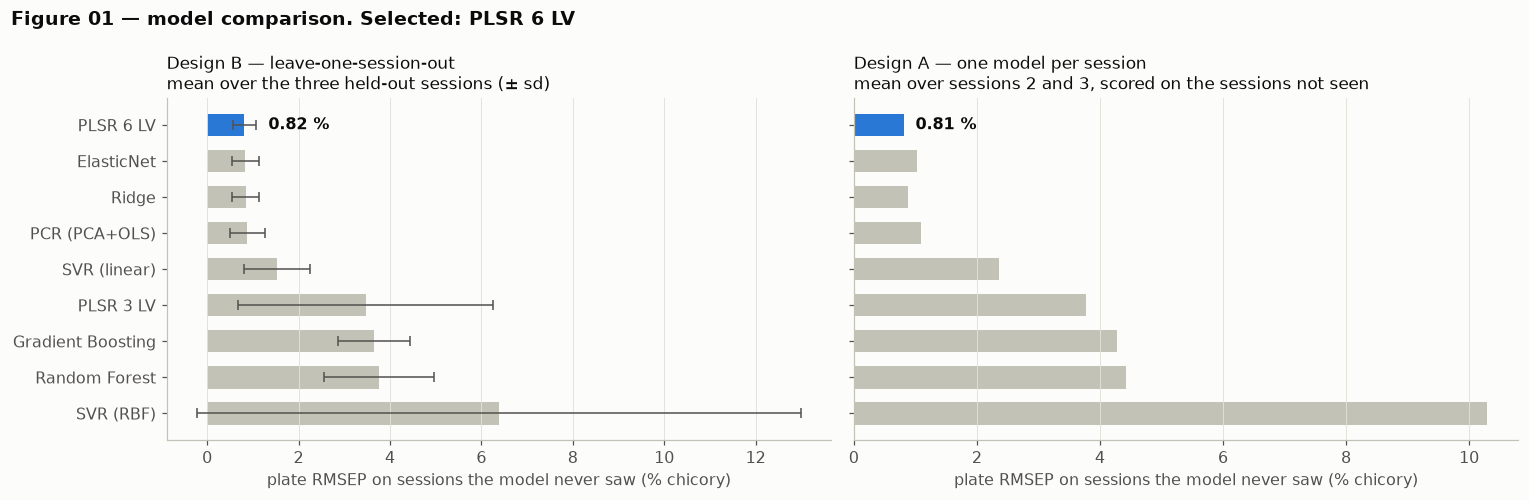

In [8]:
# Figure 01 -- the comparison that picks the model (the only figure showing all nine)
order = SUMMARY.index.tolist()
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
panels = [("loso_mean_rmsep", "loso_sd_rmsep", "Design B — leave-one-session-out\nmean over the three held-out sessions (± sd)"),
          ("A_transfer_rmsep", None, f"Design A — one model per session\nmean over sessions {' and '.join(map(str, TRAINABLE))}, scored on the sessions not seen")]
for ax, (col, err, ttl) in zip(axs, panels):
    v = SUMMARY.loc[order, col].to_numpy()
    e = SUMMARY.loc[order, err].to_numpy() if err else np.zeros(len(v))
    ax.barh(np.arange(len(order)), v, height=.62, color=[HIGHLIGHT if m == SELECTED else OTHER for m in order],
            xerr=e if err else None, error_kw=dict(ecolor=INK2, elinewidth=1, capsize=3))
    i = order.index(SELECTED)
    ax.text(v[i] + e[i], i, f"  {v[i]:.2f} %", va="center", color=INK, fontweight="bold")
    ax.set_yticks(np.arange(len(order)), order)
    ax.set_xlabel("plate RMSEP on sessions the model never saw (% chicory)")
    ax.set_title(ttl, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
axs[0].invert_yaxis()
fig.suptitle(f"Figure 01 — model comparison. Selected: {SELECTED}", x=.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "01_model_comparison.png", bbox_inches="tight"); plt.show()

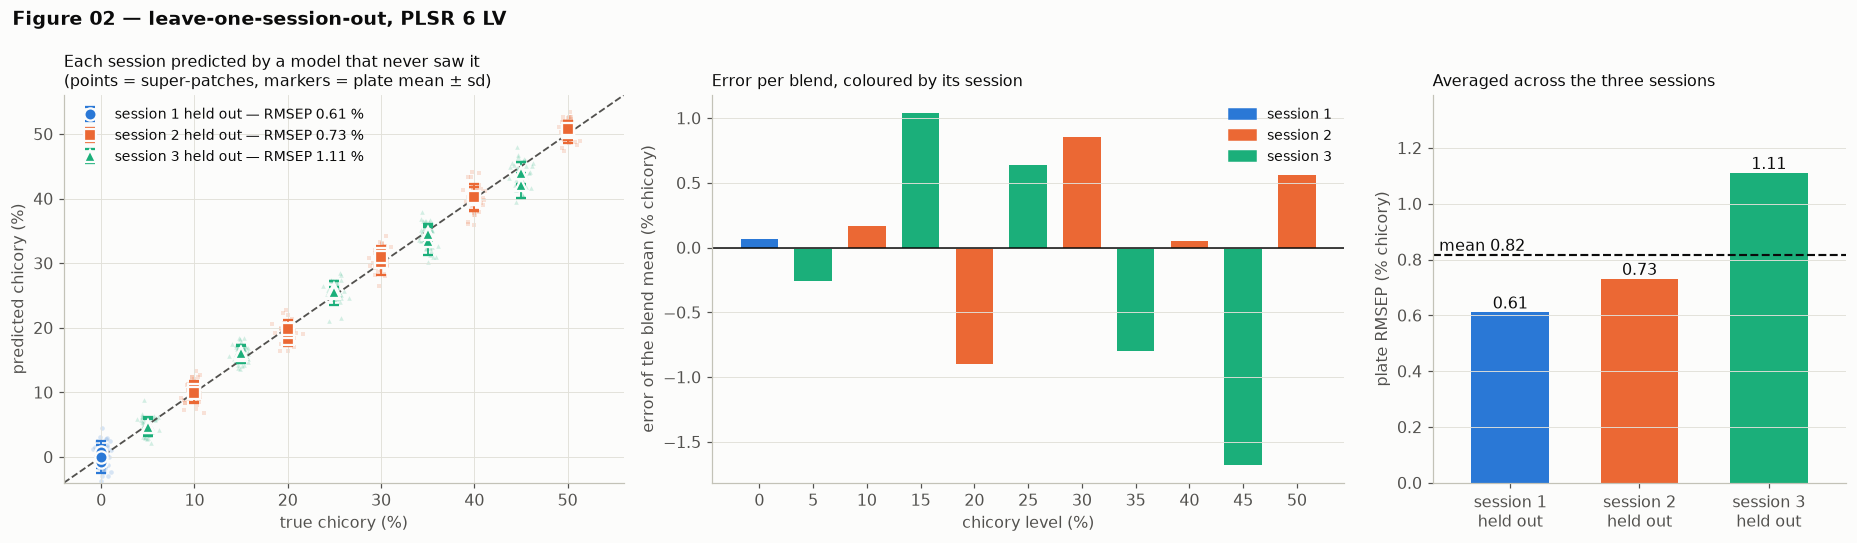

In [9]:
# Figure 02 -- leave-one-session-out, selected model only
sel = LOSO_PRED[(LOSO_PRED.model == SELECTED) & (LOSO_PRED.kind == "calibration")]
pl  = sel.groupby(["fold", "group", "y"], as_index=False).agg(p=("p", "mean"), sd=("p", "std"))
smp = sel.groupby(["fold", "label", "y"], as_index=False)["p"].mean().sort_values("y")
smp["err"] = smp.p - smp.y
FR  = LOSO_ROWS[LOSO_ROWS.model == SELECTED].set_index("held_out")
LIM = [-4, 56]

fig, axs = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw=dict(width_ratios=[1.15, 1.3, .85]))
ax = axs[0]
for s in (1, 2, 3):
    u, q = sel[sel.fold == s], pl[pl.fold == s]
    ax.scatter(u.y + RNG.normal(0, .5, len(u)), u.p, s=9, alpha=.18, color=S_COLOR[s], marker=S_MARKER[s], lw=0)
    ax.errorbar(q.y, q.p, yerr=q.sd, fmt=S_MARKER[s], ms=8, color=S_COLOR[s], mec=SURFACE, mew=1.5,
                ecolor=S_COLOR[s], elinewidth=1.2, capsize=3, zorder=4,
                label=f"session {s} held out — RMSEP {FR.loc[s, 'rmsep_plate']:.2f} %")
ax.plot(LIM, LIM, ls="--", color=INK2, lw=1.2, zorder=1)
ax.set_xlim(LIM); ax.set_ylim(LIM)
ax.set_xlabel("true chicory (%)"); ax.set_ylabel("predicted chicory (%)")
ax.set_title("Each session predicted by a model that never saw it\n(points = super-patches, markers = plate mean ± sd)",
             loc="left", fontsize=10.5)
ax.legend(loc="upper left")

ax = axs[1]
ax.bar(np.arange(len(smp)), smp.err, width=.7, color=[S_COLOR[s] for s in smp.fold])
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(np.arange(len(smp)), [f"{v:.0f}" for v in smp.y])
ax.set_xlabel("chicory level (%)"); ax.set_ylabel("error of the blend mean (% chicory)")
ax.set_title("Error per blend, coloured by its session", loc="left", fontsize=10.5)
ax.legend(handles=[Patch(color=S_COLOR[s], label=f"session {s}") for s in (1, 2, 3)], loc="best")
ax.grid(axis="x", visible=False)

ax = axs[2]
vals = [FR.loc[s, "rmsep_plate"] for s in (1, 2, 3)]
ax.bar([1, 2, 3], vals, width=.6, color=[S_COLOR[s] for s in (1, 2, 3)])
for s, v in zip((1, 2, 3), vals):
    ax.text(s, v, f"{v:.2f}", ha="center", va="bottom", color=INK)
mean_v = SUMMARY.loc[SELECTED, "loso_mean_rmsep"]
ax.axhline(mean_v, color=INK, ls="--", lw=1.4)
ax.text(.45, mean_v, f"mean {mean_v:.2f}", va="bottom", color=INK)
ax.set_xlim(.4, 3.6); ax.set_ylim(0, max(vals) * 1.25)
ax.set_xticks([1, 2, 3], [f"session {s}\nheld out" for s in (1, 2, 3)])
ax.set_ylabel("plate RMSEP (% chicory)")
ax.set_title("Averaged across the three sessions", loc="left", fontsize=10.5)
ax.grid(axis="x", visible=False)
fig.suptitle(f"Figure 02 — leave-one-session-out, {SELECTED}", x=.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "02_loso_selected.png", bbox_inches="tight"); plt.show()

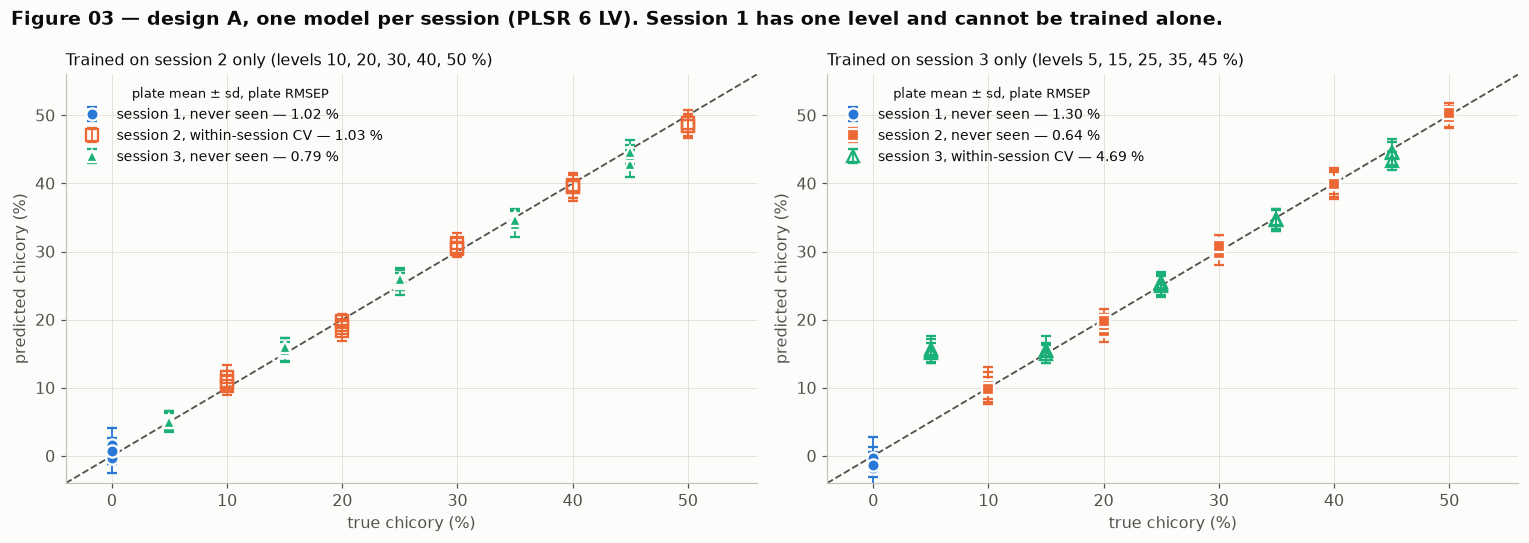

In [10]:
# Figure 03 -- design A, one model per session, selected method only
def ps_val(s, t):
    r = PS_ROWS[(PS_ROWS.model == SELECTED) & (PS_ROWS.train == s) & (PS_ROWS.test == t)]
    return float(r.rmsep_plate.iloc[0])

fig, axs = plt.subplots(1, len(TRAINABLE), figsize=(7 * len(TRAINABLE), 5), squeeze=False)
for ax, s in zip(axs[0], TRAINABLE):
    d = PS_PRED[(PS_PRED.model == SELECTED) & (PS_PRED.train == s) & (PS_PRED.kind == "calibration")]
    q = d.groupby(["test", "group", "y"], as_index=False).agg(p=("p", "mean"), sd=("p", "std"))
    for t in (1, 2, 3):
        qt = q[q.test == t]
        if not len(qt):
            continue
        own = t == s
        ax.errorbar(qt.y, qt.p, yerr=qt.sd, fmt=S_MARKER[t], ms=8, color=S_COLOR[t],
                    mfc="none" if own else S_COLOR[t], mec=S_COLOR[t] if own else SURFACE, mew=1.5,
                    ecolor=S_COLOR[t], elinewidth=1.2, capsize=3, zorder=4,
                    label=(f"session {t}, within-session CV" if own else f"session {t}, never seen")
                          + f" — {ps_val(s, t):.2f} %")
    ax.plot(LIM, LIM, ls="--", color=INK2, lw=1.2, zorder=1)
    ax.set_xlim(LIM); ax.set_ylim(LIM)
    ax.set_xlabel("true chicory (%)"); ax.set_ylabel("predicted chicory (%)")
    ax.set_title(f"Trained on session {s} only (levels {', '.join(f'{v:.0f}' for v in LEVELS[s])} %)",
                 loc="left", fontsize=10.5)
    ax.legend(loc="upper left", title="plate mean ± sd, plate RMSEP", title_fontsize=8.5)
fig.suptitle(f"Figure 03 — design A, one model per session ({SELECTED}). "
             "Session 1 has one level and cannot be trained alone.", x=.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "03_per_session_selected.png", bbox_inches="tight"); plt.show()

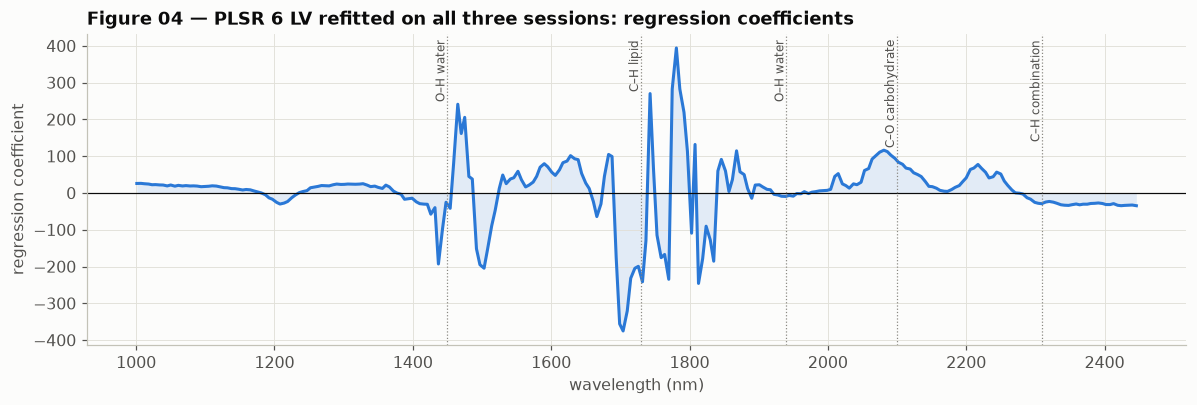

In [11]:
# Figure 04 -- what the selected model uses (linear methods only)
coef = linear_coef(FINAL)
if coef is None:
    print(f"{SELECTED} has no linear coefficients -- figure 04 skipped")
else:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.fill_between(WL, 0, coef, color=HIGHLIGHT, alpha=.12, lw=0)
    ax.plot(WL, coef, color=HIGHLIGHT, lw=2)
    ax.axhline(0, color=INK, lw=.8)
    for nm, t in BANDS:
        ax.axvline(nm, color=MUTED, lw=.8, ls=":")
        ax.text(nm, .98, t, transform=ax.get_xaxis_transform(), rotation=90, va="top", ha="right",
                fontsize=8, color=INK2)
    ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("regression coefficient")
    ax.set_title(f"Figure 04 — {SELECTED} refitted on all three sessions: regression coefficients",
                 loc="left", fontsize=12, fontweight="bold")
    plt.tight_layout(); plt.savefig(OUT / "04_coefficients_selected.png", bbox_inches="tight"); plt.show()

## 9. Predictions for the session-1 samples

Four estimates per sample, all from the selected method:

- **fold 1–3** — each LOSO fold model. A, B, C and CH100 were never used for training in any fold. RB100 is
  training data in folds 2 and 3, so only its fold-1 (held-out) value is shown.
- **LOSO mean** — the three fold predictions averaged: the session-averaged final result you asked for.
  Uncertainty = √(pooled LOSO RMSEP² + sd across folds²), so disagreement between folds widens it.
- **refit, all sessions** — the conventional final model from section 7.
- **design A** — the session-2 and session-3 models, and their average.

sample  true  fold1  fold2  fold3  loso_mean  fold_sd  uncertainty  robusta_pct  refit_all  session2_model  session3_model  designA_mean  Q_rel                                verdict
 RB100   0.0    0.1    NaN    NaN        0.1      0.0          0.9         99.9        0.1             0.7            -1.1          -0.2   1.00                           quantifiable
     A   NaN   30.1   33.1   32.3       31.8      1.5          1.8         68.2       31.2            33.2            33.4          33.3   1.65                           quantifiable
     B   NaN   50.0   47.8   51.9       49.9      2.0          2.2          NaN       50.9            48.8            49.6          49.2   4.35 outside calibrated space — detect only
     C   NaN   37.5   39.6   47.9       41.7      5.5          5.6          NaN       38.5            43.3            33.9          38.6   4.25 outside calibrated space — detect only
 CH100 100.0   87.9   86.9   84.5       86.4      1.7          2.0          NaN      

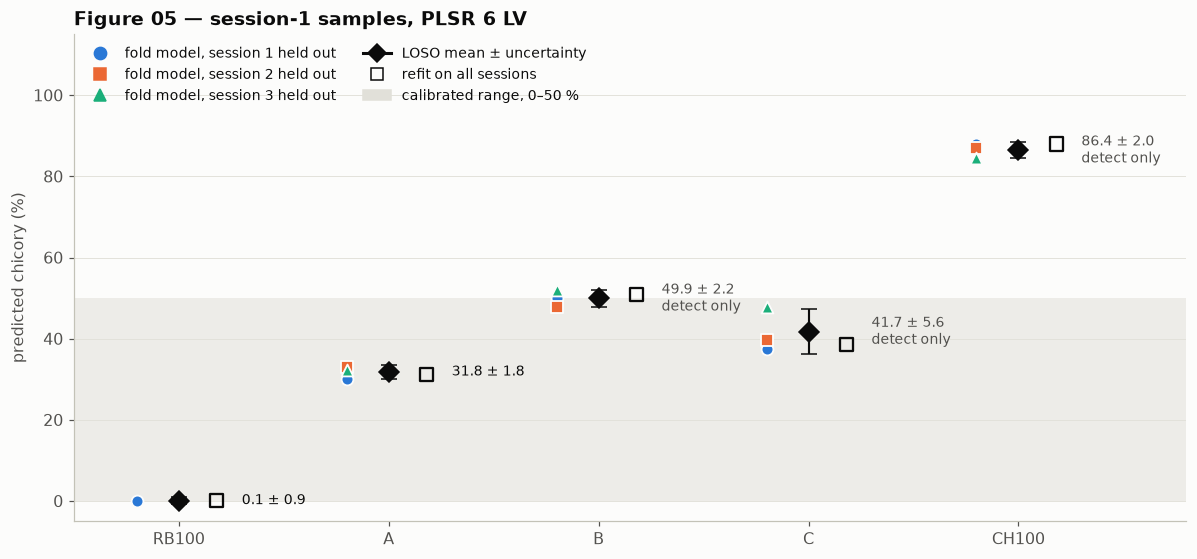

In [12]:
lo = LOSO_PRED[(LOSO_PRED.model == SELECTED) & (LOSO_PRED.session == 1)]
PER_FOLD = lo.groupby(["label", "fold"]).p.mean().unstack("fold")
ps = PS_PRED[(PS_PRED.model == SELECTED) & (PS_PRED.session == 1)]
ENS = ps.groupby(["label", "train"]).p.mean().unstack("train")
POOLED = SUMMARY.loc[SELECTED, "loso_pooled_rmsep"]
TRUE = {"RB100": 0.0, "CH100": 100.0}

rows = []
for lab in ["RB100", "A", "B", "C", "CH100"]:
    f = PER_FOLD.loc[lab].dropna()
    mean_f = float(f.mean())
    sd_f = float(f.std(ddof=1)) if len(f) > 1 else 0.0
    u = float(np.sqrt(POOLED ** 2 + sd_f ** 2))
    inside = Q_REL[lab] < 2 and -5 <= mean_f <= 55
    r = dict(sample=lab, true=TRUE.get(lab, np.nan))
    r.update({f"fold{s}": round(float(PER_FOLD.loc[lab].get(s, np.nan)), 1) for s in (1, 2, 3)})
    r.update(loso_mean=round(mean_f, 1), fold_sd=round(sd_f, 1), uncertainty=round(u, 1),
             robusta_pct=round(100 - mean_f, 1) if inside else np.nan,
             refit_all=round(float(REFIT[lab]), 1))
    r.update({f"session{s}_model": round(float(ENS.loc[lab, s]), 1) for s in TRAINABLE})
    r.update(designA_mean=round(float(ENS.loc[lab].mean()), 1), Q_rel=round(float(Q_REL[lab]), 2),
             verdict="quantifiable" if inside else "outside calibrated space — detect only")
    rows.append(r)
UNK = pd.DataFrame(rows)
print(UNK.to_string(index=False))

# Figure 05
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.axhspan(0, 50, color=GRID, alpha=.55, lw=0, zorder=0)
for i, r in UNK.iterrows():
    for s in (1, 2, 3):
        v = r[f"fold{s}"]
        if np.isfinite(v):
            ax.scatter(i - .2, v, s=60, marker=S_MARKER[s], color=S_COLOR[s], edgecolor=SURFACE, lw=1.2, zorder=4)
    ax.errorbar(i, r.loso_mean, yerr=r.uncertainty, fmt="D", ms=9, color=INK, capsize=5, lw=1.4, zorder=5)
    ax.scatter(i + .18, r.refit_all, s=75, marker="s", facecolor="none", edgecolor=INK, lw=1.5, zorder=5)
    quant = r.verdict == "quantifiable"
    ax.text(i + .3, r.loso_mean, f"{r.loso_mean:.1f} ± {r.uncertainty:.1f}" + ("" if quant else "\ndetect only"),
            va="center", fontsize=9, color=INK if quant else INK2)
handles = [Line2D([], [], ls="", marker=S_MARKER[s], ms=8, color=S_COLOR[s], label=f"fold model, session {s} held out")
           for s in (1, 2, 3)]
handles += [Line2D([], [], ls="-", marker="D", ms=8, color=INK, label="LOSO mean ± uncertainty"),
            Line2D([], [], ls="", marker="s", ms=8, mfc="none", mec=INK, label="refit on all sessions"),
            Patch(color=GRID, label="calibrated range, 0–50 %")]
ax.legend(handles=handles, loc="upper left", ncol=2)
ax.set_xticks(range(len(UNK)), UNK["sample"]); ax.set_xlim(-.5, len(UNK) - .2)
ax.set_ylim(-5, 115); ax.set_ylabel("predicted chicory (%)")
ax.grid(axis="x", visible=False)
ax.set_title(f"Figure 05 — session-1 samples, {SELECTED}", loc="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "05_session1_predictions.png", bbox_inches="tight"); plt.show()

## 10. Saving the results

In [13]:
def clean(v):
    if isinstance(v, (float, np.floating)):
        return None if not np.isfinite(v) else round(float(v), 3)
    if isinstance(v, (np.integer,)):
        return int(v)
    return v

LOSO_ROWS.to_csv(OUT / "loso_by_session.csv", index=False)
PS_ROWS.to_csv(OUT / "per_session_models.csv", index=False)
SUMMARY.reset_index(names="model").to_csv(OUT / "model_summary.csv", index=False)
UNK.to_csv(OUT / "predictions_session1.csv", index=False)
sel.to_csv(OUT / "loso_predictions_selected.csv", index=False)

summary = dict(
    selected_model=SELECTED,
    selection_rule="lowest mean plate RMSEP over the three held-out sessions (leave-one-session-out)",
    settings=dict(wl_nm=[WL_MIN, WL_MAX], trim_pct=TRIM_PCT, patches_per_unit=K_UNIT, n_comp=N_COMP),
    loso=dict(
        per_held_out_session={int(s): {k: clean(FR.loc[s, k]) for k in
                                       ["levels", "plates", "rmsep_plate", "rmsep_sample", "bias", "r2", "slope", "intercept"]}
                              for s in (1, 2, 3)},
        mean_rmsep_plate=clean(SUMMARY.loc[SELECTED, "loso_mean_rmsep"]),
        sd_rmsep_plate=clean(SUMMARY.loc[SELECTED, "loso_sd_rmsep"]),
        pooled_rmsep_plate=clean(SUMMARY.loc[SELECTED, "loso_pooled_rmsep"]),
        pooled_r2=clean(SUMMARY.loc[SELECTED, "loso_pooled_r2"])),
    runner_up=dict(model=RUNNER_UP, mean_rmsep_plate=clean(SUMMARY.loc[RUNNER_UP, "loso_mean_rmsep"]),
                   difference_ci95=[clean(DIFF_CI[0]), clean(DIFF_CI[1])], tie=TIE),
    per_session_models=dict(trained=TRAINABLE, skipped=[s for s in (1, 2, 3) if s not in TRAINABLE],
                            within_cv_rmsep=clean(SUMMARY.loc[SELECTED, "A_within_cv"]),
                            transfer_rmsep=clean(SUMMARY.loc[SELECTED, "A_transfer_rmsep"])),
    all_models=[{k: clean(v) for k, v in r.items()} for r in SUMMARY.reset_index(names="model").to_dict("records")],
    session1_predictions=[{k: clean(v) for k, v in r.items()} for r in UNK.to_dict("records")],
)
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))

print("=" * 72)
print(f"SELECTED MODEL: {SELECTED}")
print("=" * 72)
for s in (1, 2, 3):
    r = FR.loc[s]
    extra = "" if np.isnan(r.r2) else f"   R² {r.r2:.3f}   slope {r.slope:.3f}"
    print(f"  session {s} held out   plate RMSEP {r.rmsep_plate:5.2f} %   bias {r.bias:+5.2f}{extra}")
print(f"  mean over sessions     {SUMMARY.loc[SELECTED, 'loso_mean_rmsep']:5.2f} % "
      f"(sd {SUMMARY.loc[SELECTED, 'loso_sd_rmsep']:.2f})   pooled {POOLED:.2f} %")
print(f"  vs {RUNNER_UP}: " + ("tie" if TIE else "different") + f" (CI {DIFF_CI[0]:+.2f} to {DIFF_CI[1]:+.2f})")
print(f"  design A (per-session models): within-CV {SUMMARY.loc[SELECTED, 'A_within_cv']:.2f} %, "
      f"on unseen sessions {SUMMARY.loc[SELECTED, 'A_transfer_rmsep']:.2f} %")
for _, r in UNK.iterrows():
    if r["sample"] in ("A", "B", "C"):
        tail = f"{r.robusta_pct:.1f} % robusta" if r.verdict == "quantifiable" else "detect only"
        print(f"  {r['sample']}: {r.loso_mean:.1f} ± {r.uncertainty:.1f} % chicory (refit {r.refit_all:.1f})  -> {tail}")
print("\nsaved to", OUT)

SELECTED MODEL: PLSR 6 LV
  session 1 held out   plate RMSEP  0.61 %   bias +0.04
  session 2 held out   plate RMSEP  0.73 %   bias +0.15   R² 0.997   slope 1.017
  session 3 held out   plate RMSEP  1.11 %   bias -0.21   R² 0.994   slope 0.953
  mean over sessions      0.82 % (sd 0.26)   pooled 0.92 %
  vs ElasticNet: tie (CI -0.12 to +0.09)
  design A (per-session models): within-CV 2.86 %, on unseen sessions 0.81 %
  A: 31.8 ± 1.8 % chicory (refit 31.2)  -> 68.2 % robusta
  B: 49.9 ± 2.2 % chicory (refit 50.9)  -> detect only
  C: 41.7 ± 5.6 % chicory (refit 38.5)  -> detect only

saved to /run/media/riyanvarghese/RIYAN HDD/coffee data/session_results


## 11. Is this the standard method?

**Leave-one-session-out (design B): yes.** Holding out a whole measurement session — also called
leave-one-batch-out or between-day validation — is the accepted way to test whether a NIR or hyperspectral
calibration survives a new day, and reporting the mean ± sd of the per-session errors alongside the pooled RMSEP
is normal practice. Two cautions specific to this dataset:

- each session holds different concentrations, so every fold tests a change of session **and** a gap in
  concentration at once. Fold 1 tests only 0 %; fold 2 extrapolates to 50 %.
- the settings (6 LV, 8 patches per unit, the method hyperparameters) were chosen earlier using all three
  sessions, so this isn't fully nested. A strict version would choose them inside each fold.

**A separate model per session, averaged (design A): no.** Calibrations aren't built that way in chemometrics.
Each per-session model sees five levels over a narrower range, learns nothing about session-to-session variation,
and session 1 can't be trained at all. Standard practice is the reverse: pool the sessions in calibration so the
model learns to ignore session differences, use leave-one-session-out to measure how well that worked, then
refit on everything for the final model. Averaging the three fold models' predictions is a form of ensembling;
it's a reasonable stability check, but the conventionally reported number comes from the model refitted on all
sessions. Both are in section 9.

**When pooling isn't enough**, the standard tools are calibration-transfer methods: slope/bias correction from
transfer samples, piecewise direct standardisation (PDS), or orthogonal projection (EPO, GLSW). All of them need
at least a few samples measured in more than one session, which is what the current design lacks.